# The modes of a cantilever at work: a smooth load, a variable stiffness, a concentrated force

Companion notebook to *Variational Methods in Computational Mechanics* (S. Vidoli),
Chapter 6, Section "The Method of Eigenfunctions", Example "The Modes of a Cantilever at Work".

A cantilever of unit length, clamped at $x = 0$ and free at $x = 1$, minimizes the energy
$$\mathcal{E}(w) = \frac{1}{2}\int_0^1 EI\, (w'')^2\, dx - \ell(w), \qquad w(0) = w'(0) = 0 .$$
For $EI = 1$ the operator of the problem is $L w = w''''$, and its eigenfunctions
$$\varphi_k'''' = \lambda_k\, \varphi_k, \qquad \varphi_k(0) = \varphi_k'(0) = 0, \qquad
  \varphi_k''(1) = \varphi_k'''(1) = 0,$$
are the vibration modes of the uniform cantilever. We use the first $n$ of them as a Galerkin basis,
$w_n = \sum_k U_k \varphi_k$, $\mathbf{K}\mathbf{U} = \mathbf{f}$, for three problems:
1. **a smooth load**, $p = 1$, $EI = 1$: $\mathbf{K}$ is diagonal and the solution is the series
   $w_n = \sum_k \ell(\varphi_k)\varphi_k/\lambda_k$;
2. **a variable stiffness**, $EI(x) = 1 - 0.3\, e^{-100(x - 1/2)^2}$, same load: the modes are no longer
   eigenfunctions of the operator $(EI\, w'')''$, and $\mathbf{K}$ is full;
3. **a concentrated force** $P$ at $x_0 = 0.7$, $EI = 1$: $\mathbf{K}$ is diagonal again, but the components
   $\ell(\varphi_k) = P\varphi_k(x_0)$ of the load do not decay.

The three beams are statically determinate: the bending moment $M$ is known in closed form, and so is the exact
solution, to which every approximation is compared.

**How to use it.** Run the cells in order (*Runtime → Run all* in Colab). Then change the parameters in the next
cell and run everything again.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# ---------------------------------------------------------------- PARAMETERS
p      = 1.0                 # uniform load (problems 1 and 2)
dEI    = 0.3                 # depth of the dip of the stiffness (problem 2): EI = 1 - dEI exp(-(x - xd)^2 / w_d^2)
xd, wd = 0.5, 0.1            # centre and width of the dip
P, x0  = 1.0, 0.7            # concentrated force and its point of application (problem 3)
n_max  = 100                 # largest number of modes
n_show = 7                   # number of modes of the approximations plotted
# ---------------------------------------------------------------------------

## 1. The modes of the uniform cantilever

Setting $\lambda = \mu^4$, the general solution of $\varphi'''' = \mu^4 \varphi$ is
$\varphi = A\cos\mu x + B\sin\mu x + C\cosh\mu x + D\sinh\mu x$. The clamp gives $C = -A$, $D = -B$; the free end
gives a homogeneous $2\times 2$ system in $A, B$, with non-trivial solutions only if its determinant vanishes:
$$1 + \cos\mu \cosh\mu = 0 .$$
Its roots approach $(k - \tfrac{1}{2})\pi$ very quickly, and we find them with a bracketing method around these
values. The corresponding eigenfunctions, normalized in $L^2(0,1)$, are
$$\varphi_k = \cosh\mu_k x - \cos\mu_k x - \sigma_k (\sinh\mu_k x - \sin\mu_k x), \qquad
  \sigma_k = \frac{\sinh\mu_k - \sin\mu_k}{\cosh\mu_k + \cos\mu_k} .$$
For large $\mu$ the hyperbolic part is the difference of two huge numbers: we write it with exponentials,
$\cosh\mu x - \sigma\sinh\mu x = \tfrac{1}{2}\big[(1 - \sigma)e^{\mu x} + (1 + \sigma)e^{-\mu x}\big]$, and compute
$1 - \sigma = (e^{-\mu} + \cos\mu + \sin\mu)/(\cosh\mu + \cos\mu)$ without cancellation.

mu_k     : [ 1.8751  4.6941  7.8548 10.9955 14.1372 17.2788]
lambda_k : [1.24000e+01 4.85500e+02 3.80650e+03 1.46173e+04 3.99438e+04 8.91354e+04]
L2 Gram matrix of 100 modes: max |G - I| = 5.5e-14


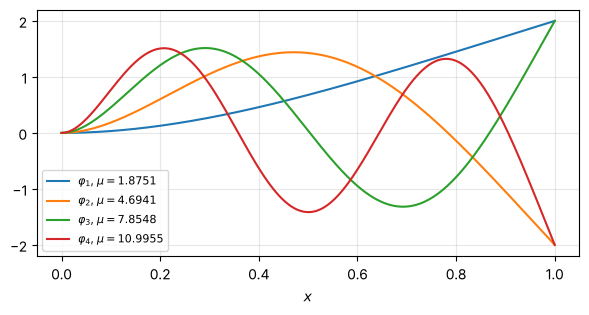

In [2]:
mu = np.array([brentq(lambda m: 1 + np.cos(m) * np.cosh(m), a - 0.6, a + 0.6)
               for a in (np.arange(1, n_max + 1) - 0.5) * np.pi])
lam = mu**4
den = np.cosh(mu) + np.cos(mu)
sg  = (np.sinh(mu) - np.sin(mu)) / den             # sigma_k
smn = (np.exp(-mu) + np.cos(mu) + np.sin(mu)) / den  # 1 - sigma_k, without cancellation

def modes(n, x):
    """Values and first three derivatives of the first n modes at the points x: array (4, n, len(x))."""
    m, s, s1 = mu[:n, None], sg[:n, None], smn[:n, None]
    ep, em = s1 * np.exp(m * x) / 2, (1 + s) * np.exp(-m * x) / 2   # (1-sigma) e^{mu x}/2, (1+sigma) e^{-mu x}/2
    c, sn = np.cos(m * x), np.sin(m * x)
    return np.array([ep + em - c + s * sn,
                     m    * (ep - em + sn + s * c),
                     m**2 * (ep + em + c - s * sn),
                     m**3 * (ep - em - sn - s * c)])

def quadrature(nq, ng=16):
    """Gauss-Legendre points and weights on (0,1) divided into nq equal intervals."""
    g, wg = np.polynomial.legendre.leggauss(ng)
    return (np.concatenate([(e + (g + 1) / 2) / nq for e in range(nq)]),
            np.concatenate([wg / 2 / nq] * nq))

xq, wq = quadrature(1000)     # x0 = 0.7 falls on an interval end: piecewise polynomials are integrated exactly
B = modes(n_max, xq)
print("mu_k     :", np.round(mu[:6], 4))
print("lambda_k :", np.round(lam[:6], 1))
G = (B[0] * wq) @ B[0].T
print(f"L2 Gram matrix of {n_max} modes: max |G - I| = {np.abs(G - np.eye(n_max)).max():.1e}")

xs = np.linspace(0, 1, 801)
fig, ax = plt.subplots(figsize=(7, 3.2))
for k, ph in enumerate(modes(4, xs)[0]):
    ax.plot(xs, ph, label=f"$\\varphi_{k+1}$, $\\mu = {mu[k]:.4f}$")
ax.set_xlabel("$x$"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

Every mode is a sine wave plus two boundary layers, $e^{-\mu x}$ at the clamp and $e^{\mu(x-1)}$ at the free end;
away from the ends $\varphi_k \approx \sqrt{2}\,\sin(\mu_k x - \pi/4)$, so that $\varphi_k(1) = \pm 2$.

## 2. A smooth load

For $EI = 1$ the stiffness matrix is diagonal, $K_{kh} = \lambda_k \delta_{kh}$, and each coordinate is computed on
its own, $U_k = \ell(\varphi_k)/\lambda_k$, with $\ell(\varphi_k) = p\int_0^1 \varphi_k\, dx = 2p\,\sigma_k/\mu_k$.
The exact solution is $w = p\, x^2(6 - 4x + x^2)/24$. We measure the relative $L^2$ error of the deflection $w$,
the rotation $w'$, the curvature $w''$ and the shear $w'''$.

   n      w          w'         w''        w'''
   1   1.42e-02   3.64e-02   9.03e-02   2.56e-01
   2   1.08e-03   4.17e-03   2.00e-02   9.84e-02
   4   6.04e-05   4.04e-04   3.89e-03   3.62e-02
   8   2.89e-06   3.64e-05   7.06e-04   1.29e-02
  16   1.30e-07   3.23e-06   1.26e-04   4.59e-03
  32   5.79e-09   2.86e-07   2.23e-05   1.62e-03


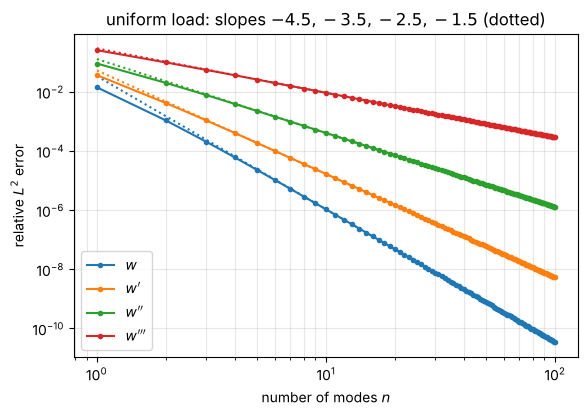

In [3]:
def rel_errors(U, exact):
    """Relative L2 errors of w, w', w'', w''' of w_n = sum U_k phi_k, for n = 1 .. len(U)."""
    out = []
    for j in range(4):
        part = np.cumsum(U[:, None] * B[j, :len(U)], axis=0)     # partial sums, (n, points)
        out.append(np.sqrt(((part - exact[j])**2) @ wq / (exact[j]**2 @ wq)))
    return np.array(out)

x = xq
w_p = [p * x**2 * (6 - 4*x + x**2) / 24, p * x * (3 - 3*x + x**2) / 6, p * (1 - x)**2 / 2, -p * (1 - x)]
f_p = (B[0] * p) @ wq                        # = 2 p sigma_k / mu_k
U_p = f_p / lam
err_p = rel_errors(U_p, w_p)

ns = np.arange(1, n_max + 1)
names = ["$w$", "$w'$", "$w''$", "$w'''$"]
print("   n      w          w'         w''        w'''")
for n in [1, 2, 4, 8, 16, 32]:
    print(f"{n:4d}  " + "  ".join(f"{e:9.2e}" for e in err_p[:, n - 1]))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for j in range(4):
    l, = ax.loglog(ns, err_p[j], "o-", ms=3, label=names[j])
    ax.loglog(ns, err_p[j, 9] * (ns / 10.0)**(j - 4.5), ":", color=l.get_color())
ax.set_xlabel("number of modes $n$"); ax.set_ylabel("relative $L^2$ error")
ax.set_title("uniform load: slopes $-4.5, -3.5, -2.5, -1.5$ (dotted)")
ax.grid(True, which="both", alpha=0.3); ax.legend()
plt.show()

The components of the load decay like $1/k$ and the eigenvalues grow like $k^4$: the coordinates decay like
$k^{-5}$. Each derivative of $\varphi_k$ brings a factor $\mu_k \sim k$, so the error of the $j$-th derivative
decreases like $n^{j - 9/2}$: each derivative costs one order of convergence. The shear force $w'''$ is the last to
converge, and near the free end, where $w'''$ does not vanish but every $\varphi_k'''$ does, it never quite does.

## 3. A variable stiffness, with the same modes

Now $EI(x) = 1 - 0.3\, e^{-100(x - 1/2)^2}$: a smooth, localized weakening. The modes of the uniform cantilever
are no longer eigenfunctions of $(EI\, w'')''$, but they still satisfy the essential conditions, and they are still a
basis. The stiffness matrix
$$K_{kh} = \int_0^1 EI\, \varphi_k''\, \varphi_h''\, dx = \lambda_k \delta_{kh}
  - 0.3 \int_0^1 e^{-100(x - 1/2)^2}\, \varphi_k''\, \varphi_h''\, dx$$
is full: a diagonal matrix plus a perturbation. The bending moment is still $M = p(1-x)^2/2$, the exact curvature
is $w'' = M/EI$, and the exact energy is $\mathcal{E}(w) = -\tfrac{1}{2}\int_0^1 M^2/EI\, dx$; the relative error in
the energy norm follows from the energy of $w_n$ alone,
$\|w - w_n\|_a/\|w\|_a = \sqrt{(\mathcal{E}(w_n) - \mathcal{E}(w))/(-\mathcal{E}(w))}$.

K / sqrt(diag K diag K), first 6 x 6 block:
[[ 1.     0.052  0.004 -0.04  -0.008  0.025]
 [ 0.052  1.     0.006  0.085 -0.003 -0.057]
 [ 0.004  0.006  1.    -0.002  0.033  0.001]
 [-0.04   0.085 -0.002  1.    -0.     0.059]
 [-0.008 -0.003  0.033 -0.     1.     0.   ]
 [ 0.025 -0.057  0.001  0.059  0.     1.   ]]

   n   energy error (EI var.)  energy error (EI = 1)  curvature error (EI var.)
   1       6.90e-02              9.03e-02              7.00e-02
   2       5.62e-02              2.00e-02              6.09e-02
   4       3.29e-02              3.89e-03              3.55e-02
   8       1.06e-02              7.06e-04              1.13e-02
  16       6.56e-04              1.26e-04              6.98e-04
  32       2.20e-05              2.23e-05              2.17e-05
  64       3.89e-06              3.95e-06              3.84e-06


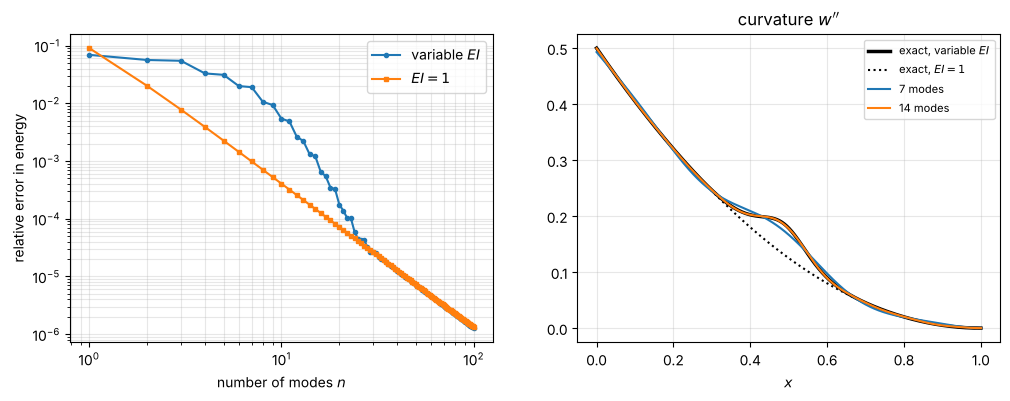

In [4]:
EI = 1 - dEI * np.exp(-((xq - xd) / wd)**2)
M = p * (1 - xq)**2 / 2
E_ex = -0.5 * np.sum(wq * M**2 / EI)
K_full = (B[2] * EI * wq) @ B[2].T
D = np.sqrt(np.diag(K_full))
print("K / sqrt(diag K diag K), first 6 x 6 block:")
print(np.round(K_full[:6, :6] / np.outer(D[:6], D[:6]), 3))

def energy_error(n):
    U = np.linalg.solve(K_full[:n, :n], f_p[:n])
    return np.sqrt(max(-0.5 * U @ f_p[:n] - E_ex, 0) / -E_ex), U

E0 = -0.5 * np.sum(wq * M**2)                      # uniform beam, for comparison
err_E   = np.array([energy_error(n)[0] for n in ns])
err_E0  = np.sqrt(np.maximum(-0.5 * np.cumsum(U_p * f_p) - E0, 0) / -E0)
err_K2  = np.array([np.sqrt(((energy_error(n)[1] @ B[2, :n] - M / EI)**2) @ wq / ((M / EI)**2 @ wq)) for n in ns])
print("\n   n   energy error (EI var.)  energy error (EI = 1)  curvature error (EI var.)")
for n in [1, 2, 4, 8, 16, 32, 64]:
    print(f"{n:4d}   {err_E[n-1]:12.2e}          {err_E0[n-1]:12.2e}          {err_K2[n-1]:12.2e}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.loglog(ns, err_E, "o-", ms=3, label="variable $EI$")
a1.loglog(ns, err_E0, "s-", ms=3, label="$EI = 1$")
a1.set_xlabel("number of modes $n$"); a1.set_ylabel("relative error in energy"); a1.legend()
a1.grid(True, which="both", alpha=0.3)
Mx = p * (1 - xs)**2 / 2; EIx = 1 - dEI * np.exp(-((xs - xd) / wd)**2)
a2.plot(xs, Mx / EIx, "k", lw=2.5, label="exact, variable $EI$")
a2.plot(xs, Mx, "k:", label="exact, $EI = 1$")
for n in sorted({n_show, 2 * n_show}):
    a2.plot(xs, energy_error(n)[1] @ modes(n, xs)[2], label=f"{n} modes")
a2.set_xlabel("$x$"); a2.set_title("curvature $w''$"); a2.grid(alpha=0.3); a2.legend(fontsize=8)
plt.show()

The off-diagonal terms are at most a few percent of the diagonal ones: the matrix is a small perturbation of a
diagonal one, and perfectly conditioned. The dip of the stiffness is smooth, the exact solution is smooth, and the
error decreases as fast as for the uniform beam; only, the modes must be numerous enough to resolve the width of
the dip: with seven modes, whose shortest half-wave is about $\pi/\mu_7 \approx 0.15$, the bump of the curvature is
caught, but not its shape. The eigenfunctions of a simpler problem are a good basis for a problem "not too far
away", provided its essential boundary conditions are the same.

## 4. A concentrated force

Back to $EI = 1$, with a force $P$ at $x_0$: $\ell(v) = P\, v(x_0)$. In one dimension this functional is bounded on
$H^2$, since $|v(x_0)| \le C \|v\|_{H^2}$, and the Riesz theorem applies: the solution has finite energy. But it is
less regular than before: the shear $w''' = -P$ for $x < x_0$, $0$ beyond, jumps at $x_0$, and $w \notin H^4$.
The matrix is still diagonal, $U_k = P\varphi_k(x_0)/\lambda_k$, but the components of the load do not decay.

   n      w          w'         w''        w'''
   1   1.41e-02   4.62e-02   1.09e-01   3.03e-01
   2   3.66e-03   1.61e-02   6.86e-02   2.88e-01
   4   2.12e-04   2.00e-03   1.89e-02   1.81e-01
   8   3.11e-05   4.58e-04   8.18e-03   1.38e-01
  16   2.42e-06   6.86e-05   2.67e-03   9.47e-02
  32   2.31e-07   1.29e-05   9.78e-04   6.78e-02
  64   1.91e-08   2.17e-06   3.36e-04   4.75e-02


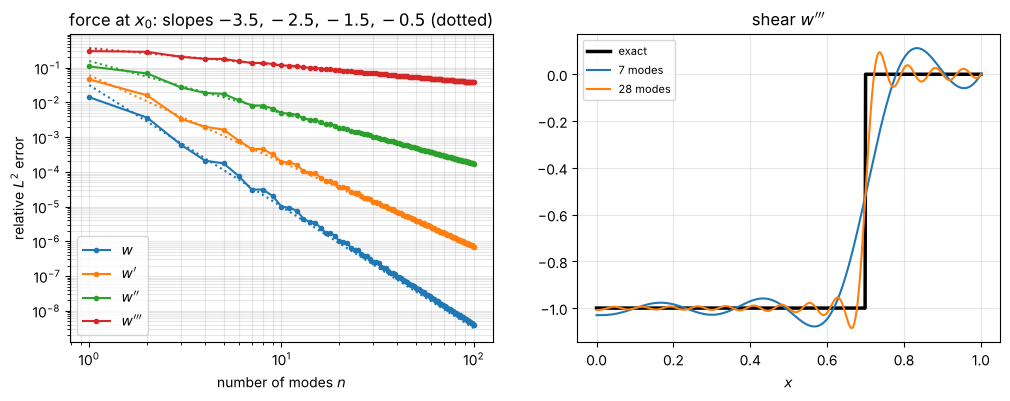

In [5]:
w_P = [np.where(x < x0, P * x**2 * (3*x0 - x) / 6, P * x0**2 * (3*x - x0) / 6),
       np.where(x < x0, P * x * (2*x0 - x) / 2, P * x0**2 / 2),
       np.where(x < x0, P * (x0 - x), 0.0),
       np.where(x < x0, -P, 0.0)]
f_P = P * modes(n_max, np.array([x0]))[0, :, 0]
U_P = f_P / lam
err_P = rel_errors(U_P, w_P)
print("   n      w          w'         w''        w'''")
for n in [1, 2, 4, 8, 16, 32, 64]:
    print(f"{n:4d}  " + "  ".join(f"{e:9.2e}" for e in err_P[:, n - 1]))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for j in range(4):
    l, = a1.loglog(ns, err_P[j], "o-", ms=3, label=names[j])
    a1.loglog(ns, err_P[j, 9] * (ns / 10.0)**(j - 3.5), ":", color=l.get_color())
a1.set_xlabel("number of modes $n$"); a1.set_ylabel("relative $L^2$ error")
a1.set_title("force at $x_0$: slopes $-3.5, -2.5, -1.5, -0.5$ (dotted)")
a1.grid(True, which="both", alpha=0.3); a1.legend()
xe = xs
a2.plot(xe, np.where(xe < x0, -P, 0.0), "k", lw=2.5, label="exact")
for n in sorted({n_show, 4 * n_show}):
    a2.plot(xe, U_P[:n] @ modes(n, xe)[3], label=f"{n} modes")
a2.set_xlabel("$x$"); a2.set_title("shear $w'''$"); a2.grid(alpha=0.3); a2.legend(fontsize=8)
plt.show()

The coordinates now decay like $k^{-4}$ instead of $k^{-5}$, and every error loses one order: $n^{-3.5}$ for the
deflection, $n^{-1.5}$ for the curvature, hence $n^{-3/2}$ for the energy, and only $n^{-1/2}$ for the shear,
which oscillates around its jump like a Fourier series around a discontinuity (the Gibbs phenomenon). The
deflection is still excellent; the shear force is not. A basis of smooth functions is not the right tool for a
solution with a jump: functions with local support, with a node at $x_0$, are (Section 6.3).

## Things to try
1. Set `dEI = 0.0`: problem 2 becomes problem 1, and the matrix $\mathbf{K}$ is diagonal again.
2. Make the dip narrower, `wd = 0.02`: how many modes are needed before the error starts to decrease fast?
   Compare the width of the dip with the half-wavelength $\pi/\mu_n$ of the last mode.
3. Make the dip deeper, `dEI = 0.9`, and print the off-diagonal terms of $\mathbf{K}$: is $\mathbf{K}$ still a
   small perturbation of a diagonal matrix? Does the convergence suffer?
4. Move the force to the free end, `x0 = 1.0`: now $\ell(\varphi_k) = \pm 2P$ and the shear $w''' = -P$ is constant
   on the whole beam, yet the series must reproduce it with functions whose third derivative vanishes at $x = 1$.
   Where does the error of $w'''$ concentrate?
5. Put the force at a node of a mode, for instance $x_0 = 0.5$: which coordinates $U_k$ vanish, and why?